FIRST FIVE ROWS
   Order_ID Region     Category       Sales  Quantity  Discount      Profit
0         1   East    Furniture  244.492634         2      0.09  167.803907
1         2   West  Electronics  491.667845         4      0.18   60.271974
2         3  North  Electronics  557.609817         6      0.08   72.465421
3         4   East    Furniture  495.095788         3      0.02  147.214482
4         5   East  Electronics  189.883685         1      0.15   57.032986

DATASET SHAPE: (500, 7)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  500 non-null    int64  
 1   Region    500 non-null    str    
 2   Category  500 non-null    str    
 3   Sales     500 non-null    float64
 4   Quantity  500 non-null    int32  
 5   Discount  500 non-null    float64
 6   Profit    500 non-null    float64
dtypes: float64(3), int32(1), int64(1)

C:\Users\HP\AppData\Local\Temp\ipykernel_22984\239134956.py:47: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))
C:\Users\HP\AppData\Local\Temp\ipykernel_22984\239134956.py:55: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html

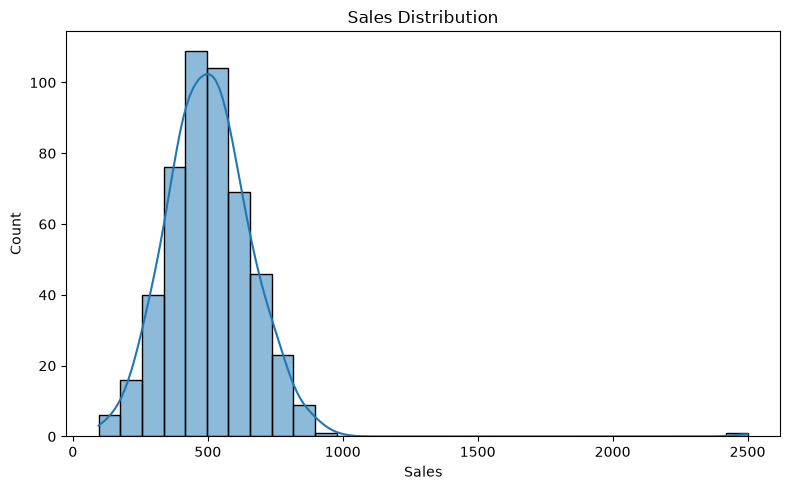


Sales OUTLIERS
Lower bound: 120.08
Upper bound: 883.06
Number of outliers: 7

Profit OUTLIERS
Lower bound: -28.18
Upper bound: 231.04
Number of outliers: 5


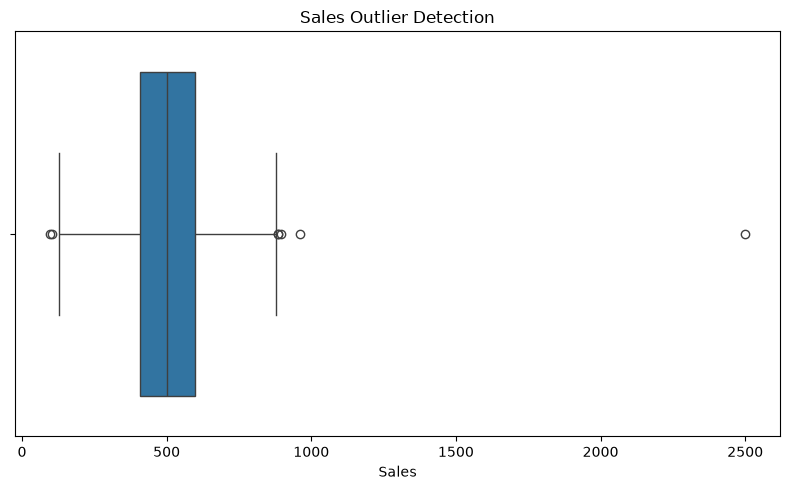


TOTAL SALES BY REGION
Region
West     73344.692411
North    64614.332300
East     63084.885218
South    52169.055160
Name: Sales, dtype: float64


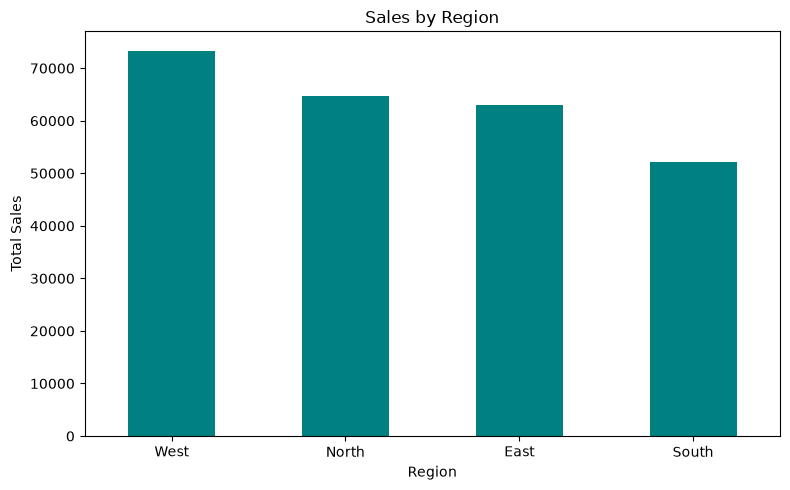


TOTAL SALES BY CATEGORY
Category
Electronics    92069.605504
Clothing       86111.610212
Furniture      75031.749373
Name: Sales, dtype: float64


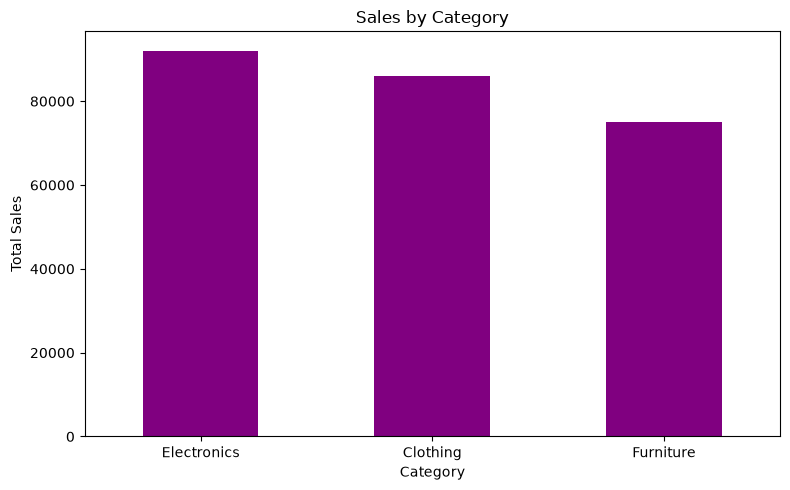

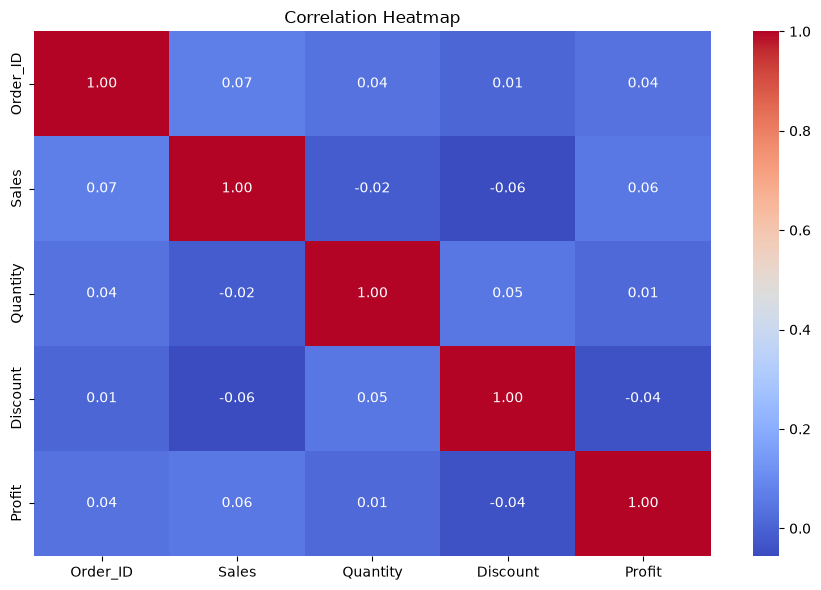

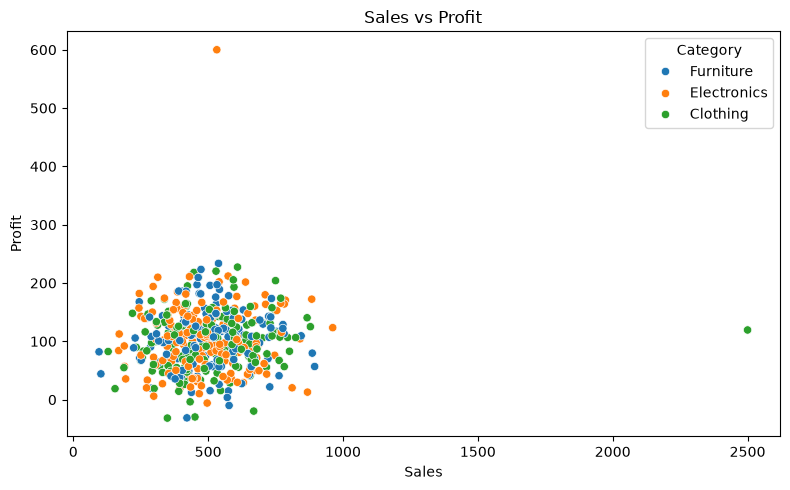


========== BUSINESS INSIGHTS ==========
Highest sales region: West
Sales in best region: 73344.69
Most profitable category: Electronics
Profit from best category: 19628.49
Total sales: 253212.97
Total profit: 51549.84
Average sales per order: 506.43
Lowest average-profit region: East
Average profit in that region: 98.46

 
EXPLORATORY DATA ANALYSIS REPORT

DATASET OVERVIEW
Rows: 500
Columns: 7
Missing values: 0
Duplicate rows: 0

DESCRIPTIVE STATISTICS
         Sales  Quantity  Discount  Profit
count   500.00    500.00    500.00  500.00
mean    506.43      5.48      0.19  103.10
std     173.08      2.90      0.11   52.93
min      95.47      1.00      0.00  -31.57
25%     406.20      3.00      0.09   69.03
50%     500.45      5.50      0.19  104.29
75%     596.94      8.00      0.30  133.83
max    2500.00     10.00      0.40  600.00

BUSINESS FINDINGS
Highest sales region: West
Most profitable category: Electronics
Total sales: 253212.97
Total profit: 51549.84
Average sales per order: 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and create sample dataset
np.random.seed(42)
n = 500

df = pd.DataFrame({
    "Order_ID": range(1, n + 1),
    "Region": np.random.choice(["North", "South", "East", "West"], n),
    "Category": np.random.choice(
        ["Electronics", "Clothing", "Furniture"], n
    ),
    "Sales": np.random.normal(500, 150, n).clip(50, None),
    "Quantity": np.random.randint(1, 11, n),
    "Discount": np.random.uniform(0, 0.40, n).round(2),
    "Profit": np.random.normal(100, 50, n)
})

# Add unusual values for outlier analysis
df.loc[10, "Sales"] = 2500
df.loc[25, "Profit"] = 600

df.to_csv("sales_data.csv", index=False)

# 2. Dataset overview
print("FIRST FIVE ROWS")
print(df.head())

print("\nDATASET SHAPE:", df.shape)

print("\nDATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATES:", df.duplicated().sum())

# 3. Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
print(df.describe())

print("\nCATEGORICAL SUMMARY")
print(df.describe(include="object"))

# 4. Data cleaning
df = df.drop_duplicates().copy()

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# 5. Sales distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Sales"], bins=30, kde=True)
plt.title("Sales Distribution")
plt.tight_layout()
plt.show()

# 6. Detect outliers using IQR
def detect_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower) | (data[column] > upper)
    ]

    print(f"\n{column} OUTLIERS")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Number of outliers:", len(outliers))
    return outliers

sales_outliers = detect_outliers(df, "Sales")
profit_outliers = detect_outliers(df, "Profit")

# 7. Sales box plot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Sales"])
plt.title("Sales Outlier Detection")
plt.tight_layout()
plt.show()

# 8. Sales by region
region_sales = df.groupby("Region")["Sales"].sum().sort_values(
    ascending=False
)

print("\nTOTAL SALES BY REGION")
print(region_sales)

region_sales.plot(kind="bar", color="teal", figsize=(8, 5))
plt.title("Sales by Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 9. Sales by category
category_sales = df.groupby("Category")["Sales"].sum().sort_values(
    ascending=False
)

print("\nTOTAL SALES BY CATEGORY")
print(category_sales)

category_sales.plot(kind="bar", color="purple", figsize=(8, 5))
plt.title("Sales by Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 11. Relationship between sales and profit
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Category")
plt.title("Sales vs Profit")
plt.tight_layout()
plt.show()

# 12. Business questions
region_sales = df.groupby("Region")["Sales"].sum()
category_profit = df.groupby("Category")["Profit"].sum()
region_profit = df.groupby("Region")["Profit"].mean()

best_region = region_sales.idxmax()
best_category = category_profit.idxmax()
lowest_profit_region = region_profit.idxmin()

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
average_sales = df["Sales"].mean()

print("\n========== BUSINESS INSIGHTS ==========")
print("Highest sales region:", best_region)
print("Sales in best region:", round(region_sales.max(), 2))
print("Most profitable category:", best_category)
print("Profit from best category:", round(category_profit.max(), 2))
print("Total sales:", round(total_sales, 2))
print("Total profit:", round(total_profit, 2))
print("Average sales per order:", round(average_sales, 2))
print("Lowest average-profit region:", lowest_profit_region)
print("Average profit in that region:", round(region_profit.min(), 2))

# 13. Generate EDA report
report = f"""
EXPLORATORY DATA ANALYSIS REPORT
================================

DATASET OVERVIEW
Rows: {df.shape[0]}
Columns: {df.shape[1]}
Missing values: {df.isnull().sum().sum()}
Duplicate rows: {df.duplicated().sum()}

DESCRIPTIVE STATISTICS
{df[['Sales', 'Quantity', 'Discount', 'Profit']].describe().round(2).to_string()}

BUSINESS FINDINGS
Highest sales region: {best_region}
Most profitable category: {best_category}
Total sales: {total_sales:.2f}
Total profit: {total_profit:.2f}
Average sales per order: {average_sales:.2f}
Lowest average-profit region: {lowest_profit_region}

OUTLIERS
Sales outliers: {len(sales_outliers)}
Profit outliers: {len(profit_outliers)}

CONCLUSION
This analysis examines sales distributions, regional performance,
category profitability, variable relationships, and outliers.
Investigate unusual transactions before deciding whether to remove them.
Correlation does not prove causation.

Note: Findings are based on randomly generated sample data.
"""

print("\n", report)

with open("eda_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

df.to_csv("cleaned_sales_data.csv", index=False)

print("\nEDA COMPLETED SUCCESSFULLY!")
print("Files saved: sales_data.csv, cleaned_sales_data.csv, eda_report.txt")